# ПР1. Исследование качества набора данных для обучения глубокой модели

**Курс:** «Безопасность и доверенность систем ИИ». **Команда:** Андрусенко К.А., Синёв В.Е., Шестакова М.А., гр. 1379.

**Задача:** регрессия оценочной стоимости строительных работ `VALUATION` по разрешению на строительство в Лос-Анджелесе (цель — `log1p(VALUATION)`, основная метрика RMSLE, меньше — лучше). Сценарий применения: проверка адекватности оценки и поиск аномально заниженных или завышенных оценок.
**Модель:** FT-Transformer (собственная реализация на PyTorch), зафиксированный baseline C96: текст `WORK_DESC` подаётся SVD-токеном и до 96 слов-токенами (с 01.11.2026; прежний вариант только с SVD-токеном сохранён в `artifacts/baseline_svd64/`, причины замены — `reports/experiments/text_tokens/`).

**Служебные оценки исключены (правило R2, с 03.11.2026).** Модель обучается и оценивается только на разрешениях с несервисной оценкой: строки с `VALUATION` ∈ {$501, $301} ∪ {≤ $10} исключены из обучения, early stopping и метрик (train 7,4%, val 9,4%, test 8,8%). Это следствие находки раздела 7: такие суммы — служебные, по признакам не предсказуемы, а остатки на них огромны по построению. Разделы о **данных** (1–6, признаковая часть 8 и IsolationForest в 9) по-прежнему считаются на всех строках; разделы об **ошибке модели** (7, ошибка по годам в 8, ошибка на аномалиях в 9) — на строках без R2, служебные строки показаны отдельно.
На test без R2 новый baseline точнее прежнего C96 (обученного на всех строках) по RMSLE: 0,889 против 0,927 (парный bootstrap: −0,039 [−0,044; −0,034]). Но MdAPE у него хуже на 9,6 п.п., а доля в ±25% ниже на 3,4 п.п.: прогноз смещён вверх (средний остаток +0,13 против −0,11 у прежнего), и сильнее всего завышаются мелкие разрешения (< $5 000). Прежний C96 и отчёт ПР1 на нём — `artifacts/baseline_c96/` и `reports/pr1_c96/`.

Ноутбук **не пересчитывает** тяжёлые шаги: все таблицы и графики построены скриптом
`src/pr1_data_quality.py` (OOF-прогнозы, MinHash, MMD/C2ST, IsolationForest) и лежат в `reports/pr1/`.
Воспроизведение: `venv\Scripts\python src\pr1_data_quality.py` (кеши в `artifacts/`; пересчёт — `--force`).

**Доверительные интервалы.** Для долей — интервал Уилсона; для остальных метрик — bootstrap по объектам, B = 2000, seed = 42 (BCa при n ≤ 60 000, иначе percentile; метод указан в каждой таблице). Модель при bootstrap не переобучается. Датасет большой (сотни тысяч строк), поэтому интервалы узкие: статистическая значимость почти всегда есть, и обсуждать нужно **практическую** величину эффектов.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, A = ROOT / "reports" / "pr1", ROOT / "artifacts"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4g}".format)


def show(name, cols=None, n=None):
    df = pd.read_csv(R / f"{name}.csv")
    if cols:
        df = df[cols]
    display(df.head(n) if n else df)
    return df


def img(name, width=None):
    display(Image(filename=str(R / f"{name}.png"), width=width))

## 1. Описание набора данных

Источник — открытые данные г. Лос-Анджелес, Департамент строительства и безопасности (LADBS): два набора с одинаковой схемой
(разрешения 2010–2019 и 2020 – н. в.), выгрузка 30.10.2026. Используются только разрешения на здания трёх типов:
`Bldg-New`, `Bldg-Addition`, `Bldg-Alter/Repair` (остальные типы — Grading, Sign, Pool и др. — имеют другую природу оценки).

In [2]:
show("describe_dataset");

,Параметр,Значение
0,Источник,"Building and Safety - Building Permits Issued Between 2010 and 2019 (N) (dyxf-7hc4), https://data.lacity.org/City-Infrastructure-Service..."
1,Версия,"выгрузка 30.10.2026, данные обновлены 25.10.2026; файлы LA_BLDG_PERMITS_2010_2019_20261030.csv, LA_BLDG_PERMITS_2020_PRESENT_20261030.csv"
2,Тип задачи,"регрессия log1p(VALUATION); метрика RMSLE (меньше — лучше), доп. MdAPE, доля в ±25%"
3,Модальности,таблица (числовые и категориальные признаки) + короткий текст WORK_DESC
4,Строк в наборах,"953,873 (dyxf-7hc4: 533,366, pi9x-tg5x: 420,507)"
5,Три типа Bldg (рабочая совокупность),"760,227"
6,Исключено: VALUATION пусто / ≤ 0,"40 / 50,513"
7,Исключено: дубли без учёта ID,365
8,Строк для обучения,"709,309"
9,"Служебные оценки R2 (VALUATION ∈ {$501, $301} ∪ {≤ $10})","исключены из обучения и оценки модели: train 36,984, val 9,970, test 9,340"


In [3]:
cfg = json.loads((A / "config.json").read_text(encoding="utf-8"))
met = json.loads((A / "baseline_metrics.json").read_text(encoding="utf-8"))["test"]
display(Markdown(
    f"**Baseline C96 без R2 (зафиксирован 03.11.2026):** {cfg['model']['arch']}, {cfg['model']['n_params']:,} параметров, "
    f"лучшая эпоха {cfg['training']['best_epoch']}, устройство {cfg['device']}.  \n"
    f"Test без R2 (n = {met['n']:,}): RMSLE {met['rmsle']['estimate']:.3f} [{met['rmsle']['low']:.3f}; {met['rmsle']['high']:.3f}] ({met['rmsle']['method']}), "
    f"MdAPE {met['mdape_pct']['estimate']:.1f}% [{met['mdape_pct']['low']:.1f}; {met['mdape_pct']['high']:.1f}], "
    f"доля в ±25% {met['within25_wilson']['estimate']:.3f} [{met['within25_wilson']['low']:.3f}; {met['within25_wilson']['high']:.3f}] (Уилсон)."))
show("describe_features");

**Baseline C96 без R2 (зафиксирован 03.11.2026):** FT-Transformer (pre-LN, ReGLU, [CLS]-голова; текст — SVD-токен + слова-токены, PAD маскируется в attention), 4,321,153 параметров, лучшая эпоха 3, устройство cuda:AMD Radeon RX 7700 XT.  
Test без R2 (n = 96,952): RMSLE 0.889 [0.883; 0.895] (BCa), MdAPE 53.5% [53.1; 54.0], доля в ±25% 0.254 [0.252; 0.257] (Уилсон).

,признак,тип,преобразование
0,square_footage,числовой,log
1,height,числовой,log
2,du_changed,числовой,slog
3,adu_changed,числовой,slog
4,lat,числовой,none
5,lon,числовой,none
6,issue_year,числовой,none
7,issue_month,числовой,none
8,issue_dow,числовой,none
9,issue_doy,числовой,none


,группа,столбец
0,id,PERMIT_NBR
1,id,PIN_NBR
2,id,APN
3,id,USE_CODE
4,id,PERMIT_GROUP
5,id,REFRESH_TIME
6,id,GEOLOCATION
7,address,PRIMARY_ADDRESS
8,future,STATUS_DESC
9,future,STATUS_DATE


,часть,n,min,p1,p5,p25,медиана,p75,p95,p99,max,среднее,log1p: среднее,log1p: std,log1p: асимметрия
0,all,709309,1,501,501,3900,1e+04,4e+04,3.113e+05,1.25e+06,1.967e+09,1.398e+05,9.401,1.865,0.3559
1,train,496596,1,501,501,4000,1e+04,4e+04,3.25e+05,1.307e+06,5.838e+08,1.468e+05,9.411,1.857,0.3877
2,val,106421,1,501,501,3750,1e+04,4.5e+04,2.64e+05,1e+06,2.798e+08,1.086e+05,9.372,1.863,0.2565
3,test,106292,1,501,501,3600,9600,4.5e+04,3.25e+05,1.2e+06,1.967e+09,1.381e+05,9.388,1.902,0.3125


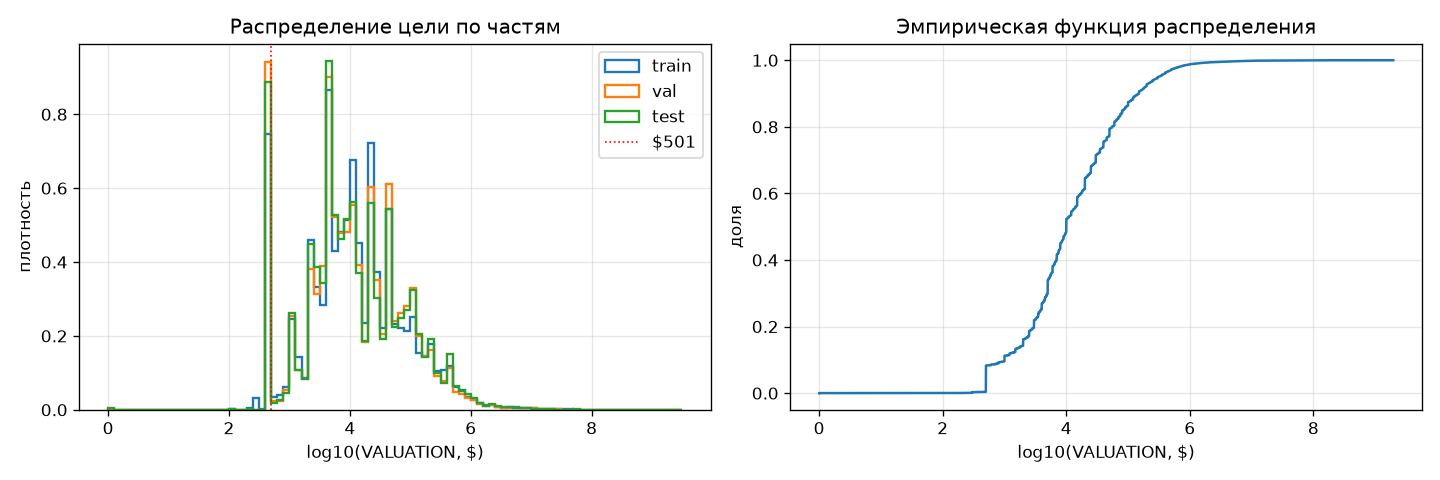

In [4]:
show("describe_excluded");
show("describe_target");
img("target_distribution")

**Интерпретация.**
* Модальности: таблица (12 числовых и 16 категориальных признаков после отбора) и короткий текст `WORK_DESC` (медиана ≈ 130 символов), который подаётся в модель двумя способами: одним SVD-токеном (TF-IDF → SVD(64)) и как последовательность до 96 слов-токенов (словарь 14 692 слова из train).
* Из признаков исключены идентификаторы (PERMIT_NBR, APN, PIN), адрес объекта, признаки «из будущего» относительно момента выдачи (STATUS_DESC, STATUS_DATE, COFO_DATE), столбцы с > 99% пропусков (JUNIOR_ADU) и константы (Solar).
* Цель сильно скошена: от $1 до ≈ $2 млрд, медиана ≈ $10 000. В log-шкале распределение близко к симметричному (асимметрия ≈ 0,36), но с **пиком на $501** (1-й и 5-й перцентили равны $501) — это служебное значение, см. раздел 7. Вместе с $301 и суммами ≤ $10 оно образует правило R2: 7,9% строк для обучения (строка «Служебные оценки R2» в первой таблице); модель на них не обучается.
* Split хронологический (70/15/15 по дате выдачи): test описывает «будущее» относительно train — это сознательный выбор, приближающий оценку к реальному применению.

## 2. Полнота

Пропуски считаются по исходным столбцам в рабочей совокупности (три типа Bldg, 760 227 строк); отдельно — по столбцам, из которых строятся признаки модели.

In [5]:
show("completeness_objects");
show("completeness_columns", n=20);

,метрика,value,ci_low,ci_high,ci_method,n
0,доля пропущенных ячеек в используемых признаках,0.2371,0.2369,0.2372,percentile,760227
1,доля объектов хотя бы с одним пропуском в используемых признаках,0.9994,0.9993,0.9994,wilson,760227
2,доля пропусков SQUARE_FOOTAGE у Bldg-New,0.02085,0.01973,0.02203,wilson,59180


,столбец,k_missing,value,ci_low,ci_high,ci_method,n,используется_в_модели
0,JUNIOR_ADU,755634,0.994,0.9938,0.9941,wilson,760227,False
1,ADU_CHANGED,707314,0.9304,0.9298,0.931,wilson,760227,True
2,DU_CHANGED,666565,0.8768,0.8761,0.8775,wilson,760227,True
3,HEIGHT,654766,0.8613,0.8605,0.8621,wilson,760227,True
4,COFO_DATE,626981,0.8247,0.8239,0.8256,wilson,760227,False
5,HL,607146,0.7986,0.7977,0.7995,wilson,760227,True
6,CONSTRUCTION,561301,0.7383,0.7373,0.7393,wilson,760227,True
7,SQUARE_FOOTAGE,559502,0.736,0.735,0.737,wilson,760227,True
8,SUBMITTED_DATE,345583,0.4546,0.4535,0.4557,wilson,760227,True
9,CNC,37484,0.04931,0.04882,0.0498,wilson,760227,True


,столбец,Bldg-Addition,Bldg-Alter/Repair,Bldg-New,1 or 2 Family Dwelling,Apartment,Commercial
0,SQUARE_FOOTAGE,0.003018,0.9075,0.02085,0.6831,0.9149,0.8065
1,HEIGHT,0.6075,0.9797,0.0006421,0.8246,0.9562,0.9389
2,CONSTRUCTION,0.0001973,0.9128,0.0002873,0.6855,0.9163,0.8096
3,DU_CHANGED,0.5249,0.9684,0.437,0.8401,0.9366,0.9892
4,ADU_CHANGED,0.7981,0.9632,0.7823,0.9059,0.9766,0.9995
5,SUBMITTED_DATE,0.0008821,0.5619,0.0004055,0.5,0.5608,0.1369
6,HL,0.7961,0.7992,0.7964,0.7522,0.8951,0.9206
7,CNC,0.05033,0.04573,0.08503,0.05246,0.05027,0.03362


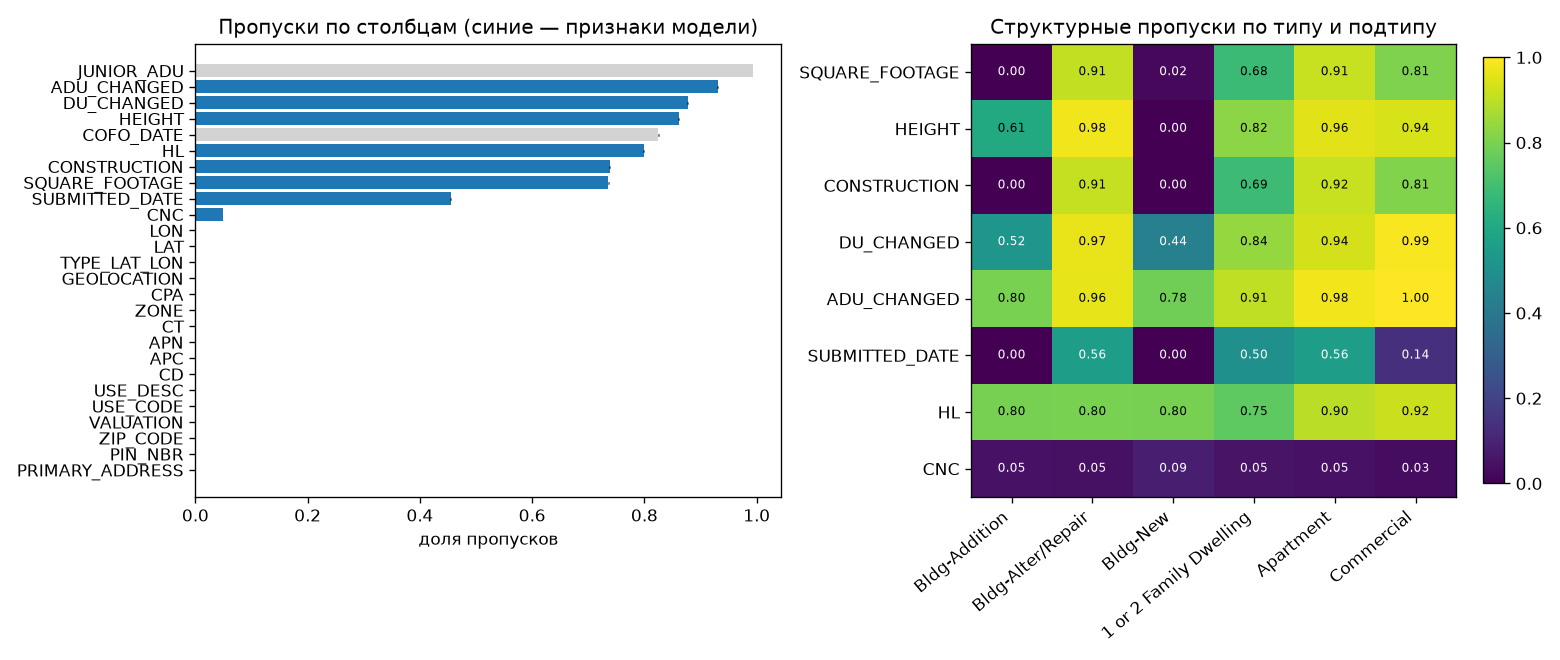

In [6]:
show("completeness_by_type");
img("completeness")

**Интерпретация.**
* Доля пропущенных ячеек в признаках модели ≈ **23,7%**, и практически **у каждого объекта (99,9%) есть хотя бы один пропуск** — модель обязана работать с неполными данными (в FT-Transformer для каждого числового признака есть обучаемый эмбеддинг «пропуск»).
* Пропуски **структурные**, а не случайные: площадь, высота и тип конструкции почти всегда заполнены у `Bldg-New` (пропуск площади 2,1% [2,0; 2,2]) и `Bldg-Addition`, но отсутствуют у ≈ 91–98% `Bldg-Alter/Repair` — а это 80% данных. Для ремонтов модель вынуждена опираться на текст и категории.
* `SUBMITTED_DATE` пропущена у ≈ 45% строк стабильно по годам. Это тоже структурный пропуск: у экспресс-разрешений (`Business Unit = Express Permit`, 45% данных, выдаются в день обращения) дата подачи не заполняется никогда, и на них приходится 98% всех пропусков этого поля.
* Следствие для ПР2: шум «пропуски» в площади/высоте затронет в основном New/Addition; у Alter/Repair эти признаки и так пусты.

## 3. Валидность

Проверяются формат, допустимые диапазоны и правила предметной области. Для проверок условных признаков знаменатель — строки, где проверка применима (например, только заполненная площадь).

,check,тип,k,знаменатель,value,ci_low,ci_high
0,VALUATION пусто,метка,40,760227,5.262e-05,3.864e-05,7.164e-05
1,VALUATION ≤ 0,метка,50513,760227,0.06644,0.06589,0.06701
2,SQUARE_FOOTAGE ≤ 0 (из заполненных),диапазон,32769,200725,0.1633,0.1616,0.1649
3,SQUARE_FOOTAGE ≤ 0 у Bldg-New (из заполненных),диапазон,3530,57946,0.06092,0.059,0.0629
4,HEIGHT ≤ 0 (из заполненных),диапазон,21,105461,0.0001991,0.0001303,0.0003044
5,HEIGHT > 1100 футов (выше самого высокого здания LA),диапазон,45,105461,0.0004267,0.0003189,0.0005709
6,DU_CHANGED > 2 у «1 or 2 Family Dwelling»,предметная область,11,85276,0.000129,7.203e-05,0.000231
7,DU_CHANGED < 0 у Bldg-New,предметная область,0,33320,0,0,0.0001153
8,ISSUE_DATE < SUBMITTED_DATE,даты,2,414644,4.823e-06,1.323e-06,1.759e-05
9,STATUS_DATE < ISSUE_DATE,даты,375,760227,0.0004933,0.0004458,0.0005458


,метрика,value,ci_low,ci_high,ci_method,n
0,доля объектов с ≥ 1 нарушением,0.1404,0.1396,0.1412,wilson,760227
1,то же среди VALUATION > 0,0.07917,0.07855,0.0798,wilson,709674


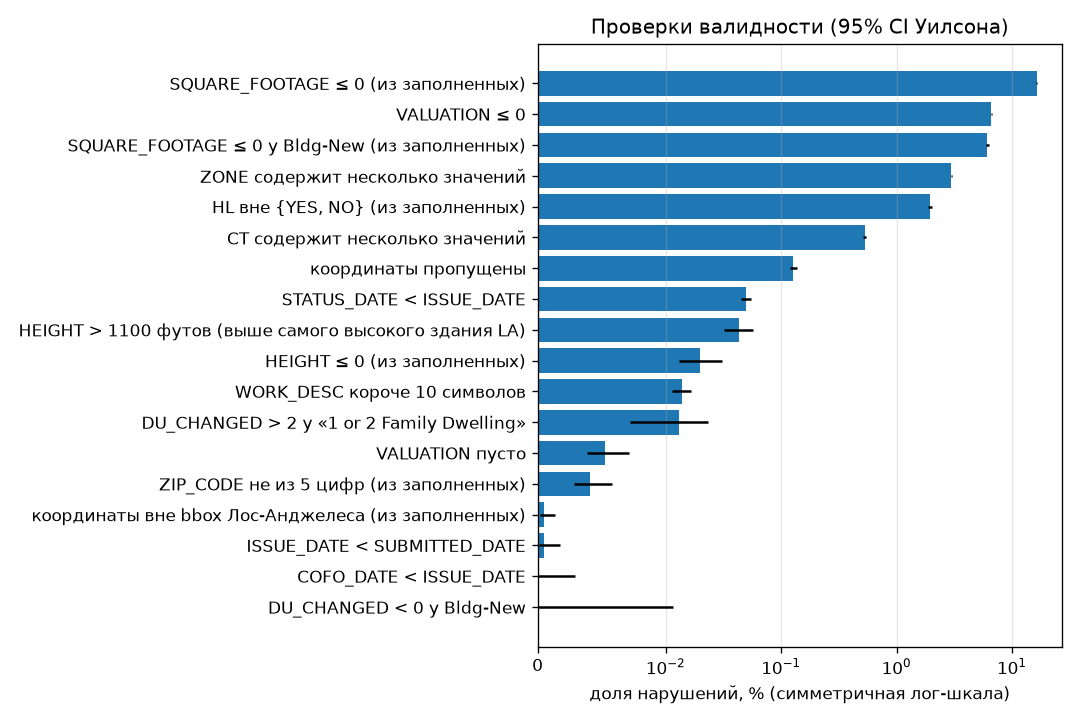

In [7]:
show("validity", cols=["check", "тип", "k", "знаменатель", "value", "ci_low", "ci_high"]);
show("validity_overall");
img("validity")

**Интерпретация.**
* **14,0% [14,0; 14,1]** объектов нарушают хотя бы одно правило; среди строк с положительной оценкой — 7,9%.
* Главные нарушения:
  * `VALUATION ≤ 0` — **6,6%** (невалидная метка; строки исключены из обучения);
  * **площадь ≤ 0 у 16,3% заполненных значений** (6,1% даже у нового строительства): ноль используется как «не указано». Это шум в одном из самых информативных признаков, и препроцессор не отличает его от реальной площади (ноль ≠ пропуск);
  * форматные проблемы: несколько значений через запятую в ZONE (3,0%) и CT (0,5%), нестандартные значения HL (`Yes`, `EXEMPT…` — 2,0% заполненных). ZIP_CODE не из 5 цифр — только 31 из заполненных значений (пустой ZIP — пропуск, он учтён в разделе 2; до 03.11.2026 пустые ZIP ошибочно считались и нарушением формата).
* Редкие, но грубые ошибки: высота > 1100 футов (45 строк, максимум 41 033), координаты вне Лос-Анджелеса (4 строки, широта ≈ 720), `STATUS_DATE < ISSUE_DATE` (375).
* Следствие для ПР3: ограничения валидности (validity constraints) для состязательных примеров нужно задавать **по правилам предметной области** (площадь > 0, высота ≤ 1100, DU_CHANGED ≤ 2 для «1 or 2 Family»), а не по «как в train» — в данных уже 14% нарушений.

## 4. Уникальность: точные и близкие дубликаты

* Точные дубли — совпадение всех столбцов; дубли без ID — всех, кроме `PERMIT_NBR` и `REFRESH_TIME`.
* Близкие дубли — тот же участок (APN), похожий текст (оценка Jaccard по MinHash, 64 перестановки, символьные 5-граммы, порог 0,9) и стоимость, отличающаяся не более чем на 10%. Учитывается более поздняя строка пары.
* У 4,6% строк APN замаскирован (последние цифры заменены на `***`): для них «тот же APN» означает тот же квартал, а не участок. Поэтому близкие дубли приводятся и отдельно — только на полных APN.
* *Исправление (01.11.2026):* в первой версии ПР1 пары искались со сдвигом индексов (строки без APN сдвигали нумерацию, и сравнивались соседние участки); доля близких дублей была занижена (0,38% вместо 2,96%), ручной разбор примеров относился к парам с разных участков.

In [8]:
show("uniqueness", cols=["check", "совокупность", "k", "n", "value", "ci_low", "ci_high"]);
show("uniqueness_supplemental_501");
show("uniqueness_near_dup_examples");

,check,совокупность,k,n,value,ci_low,ci_high
0,точные дубли (все столбцы),три типа Bldg,0,760227,0,0,5.053e-06
1,"дубли без учёта ID (PERMIT_NBR, REFRESH_TIME)",три типа Bldg,467,760227,0.0006143,0.0005611,0.0006726
2,повторы PERMIT_NBR,три типа Bldg,0,760227,0,0,5.053e-06
3,совпадают участок + текст + стоимость + тип,три типа Bldg,13978,760227,0.01839,0.01809,0.01869
4,"близкие дубли: тот же APN, Jaccard ≥ 0.9, стоимость ±10%",строки для обучения,20976,709309,0.02957,0.02918,0.02997
5,"близкий текст на том же APN (Jaccard ≥ 0.9, без условия на стоимость)",строки для обучения,34674,709309,0.04888,0.04838,0.04939
6,дополнительные разрешения («Supplemental…» в описании),строки для обучения,75820,709309,0.1069,0.1062,0.1076
7,"APN замаскирован («…***», совпадение = тот же квартал)",строки для обучения,32490,709309,0.04581,0.04532,0.04629
8,"близкие дубли, только на полных (незамаскированных) APN",строки для обучения,15965,709309,0.02251,0.02217,0.02286


,check,k,value,ci_low,ci_high,ci_method,n
0,$501 среди дополнительных разрешений,34494,0.4549,0.4514,0.4585,wilson,75820
1,$501 среди остальных,20333,0.0321,0.03167,0.03253,wilson,633489


,PERMIT_NBR_a,PERMIT_NBR_b,APN,APN замаскирован,jaccard,VALUATION_a,VALUATION_b,ISSUE_a,ISSUE_b,WORK_DESC_a,WORK_DESC_b
0,12016-10000-23234,12016-10000-23139,4118013***,True,1,4280,4130,2013-01-07,2013-01-07,SOUNDPROOFING @ LAX.,SOUNDPROOFING @ LAX.
1,17016-10000-11848,16016-10000-25986,5509003018,False,1,7000,7000,2017-05-11,2016-11-03,Kitchen/bathroom remodel for residential buildings (no structural changes).,Kitchen/bathroom remodel for residential buildings (no structural changes).
2,25016-90000-11954,25016-90000-11949,2280019030,False,1,6900,6500,2025-04-16,2025-04-16,"Remove existing roof tiles, apply new underlayment and reset roof tiles (Cool roof compliance is not required)","Remove existing roof tiles, apply new underlayment and reset roof tiles (Cool roof compliance is not required)"
3,13010-20000-03927,13010-20000-03945,2209034005,False,1,1.816e+05,1.816e+05,2015-03-18,2015-01-28,Small lot subdivision pursuant to Tentative Tract Map No./Preliminary Parcel Map No. VTT-66290. A certificate of occupancy (temporary o...,Small lot subdivision pursuant to Tentative Tract Map No./Preliminary Parcel Map No. VTT-66290. A certificate of occupancy (temporary o...
4,13010-20000-03942,13010-20000-03972,2209034005,False,1,1.816e+05,1.816e+05,2015-01-28,2015-06-11,Small lot subdivision pursuant to Tentative Tract Map No./Preliminary Parcel Map No. VTT-66290. A certificate of occupancy (temporary o...,Small lot subdivision pursuant to Tentative Tract Map No./Preliminary Parcel Map No. VTT-66290. A certificate of occupancy (temporary o...
5,16016-10000-13853,16016-10000-25977,5509003018,False,1,7000,7000,2016-06-17,2016-11-03,Kitchen/bathroom remodel for residential buildings (no structural changes).,Kitchen/bathroom remodel for residential buildings (no structural changes).
6,16016-10000-25982,21016-10000-18115,5509003018,False,1,7000,7000,2016-11-03,2021-07-13,Kitchen/bathroom remodel for residential buildings (no structural changes).,Kitchen/bathroom remodel for residential buildings (no structural changes).
7,16010-20000-01168,16010-20000-01165,2038020006,False,0.9062,2.82e+05,2.82e+05,2017-01-31,2017-01-31,"(N) 45'-0"" X 39'-4"" IRREGULAR TWO STORY SINGLE FAMILY DWELLING WITH ATTACHED TWO CAR GARAGE. FIRE SPRINKLER NFPA13D. SMALL LOT SUB-DIVI...","(N) 37'-0"" X 54'-0"" IRREGULAR TWO STORY SINGLE FAMILY DWELLING WITH ATTACHED TWO CAR GARAGE. FIRE SPRINKLER NFPA13D. SMALL LOT SUB-DIVIS..."
8,20016-10000-11627,20016-10000-11473,5055021006,False,1,9500,9500,2020-05-21,2020-05-21,1 Kitchen/1 bathroom remodel for residential buildings (no structural changes),1 Kitchen/1 bathroom remodel for residential buildings (no structural changes)
9,11016-10000-23731,11016-10000-23721,2412033***,True,0.9375,1e+04,1e+04,2011-12-05,2011-12-05,"Windows (4) and doors (3) change out (same size & type) for residential buildings. Dual glazing, labeled and certified by National Fenes...","Windows (2) and doors (3) change out (same size & type) for residential buildings. Dual glazing, labeled and certified by National Fenes..."


**Интерпретация.**
* Точных дублей нет (PERMIT_NBR уникален); **дублей без ID — 0,061%** (467 строк в рабочей совокупности; удалены до разбиения).
* **Близкие дубли — 2,96% [2,92; 3,00]** строк для обучения; только на полных APN — 2,25%. Близкий текст на том же APN без условия на стоимость — 4,89%. Полных совпадений «участок + текст + стоимость + тип» — 1,84%: это нижняя граница близких дублей.
* Ручной разбор 15 случайных пар (таблица выше) показывает, что близкие дубли — в основном **не повтор одного и того же разрешения, а однотипные разрешения на разные объекты одного участка**:
  * 6 пар — одинаковый типовой ремонт, выданный в один день (звукоизоляция у LAX, перекладка черепицы, замена окон, сайдинг, ремонт кухни и ванной) — по-видимому, на разные здания или квартиры участка;
  * 5 пар — новые дома одного small-lot subdivision или тракта: разные дома с одинаковым шаблоном описания и часто одинаковой стоимостью;
  * 4 пары — повтор того же типового ремонта на участке через месяцы–годы; три из них — один участок с серией одинаковых разрешений по $7 000 (вероятно, разные квартиры).
  * 5 пар из 15 — на замаскированных APN, то есть, возможно, на разных участках одного квартала.
* Для модели такие объекты почти идентичны по входу и метке. Это важно для OOF-проверки меток (раздел 7) и для выбора privacy unit в ПР4.
* Важная структурная находка: **10,7% разрешений — дополнительные** («Supplemental to …») и ссылаются на основное разрешение. **У 45,5% из них стоимость = $501**, против 3,2% у остальных. Значит, $501 — в первую очередь служебная стоимость дополнительных и административных разрешений.


## 5. Train-test leakage

* «Точная копия входа» — совпадение всех исходных полей, из которых строятся признаки, кроме абсолютных дат (дата выдачи заменена сроком рассмотрения), и нормализованного текста.
* Близкий дубль — пара из раздела 4, где одна строка в train, другая в val/test.
* Общие участки — участок (APN) объекта val/test встречается в train.

In [9]:
show("leakage", cols=["часть", "check", "k", "n", "value", "ci_low", "ci_high"]);
show("leakage_excluded_features");

,часть,check,k,n,value,ci_low,ci_high
0,val,точная копия входа модели в train (без абсолютного времени),87,106421,0.0008175,0.0006629,0.001008
1,val,точная копия входа и метки в train,26,106421,0.0002443,0.0001667,0.000358
2,val,"близкий дубль в train (APN + Jaccard ≥ 0,9)",1267,106421,0.01191,0.01127,0.01258
3,val,близкий дубль в train + стоимость ±10%,314,106421,0.002951,0.002642,0.003295
4,val,участок (APN) встречается в train,51441,106421,0.4834,0.4804,0.4864
5,val,"участок встречается в train, только полные APN",46952,101684,0.4617,0.4587,0.4648
6,test,точная копия входа модели в train (без абсолютного времени),19,106292,0.0001788,0.0001144,0.0002792
7,test,точная копия входа и метки в train,2,106292,1.882e-05,5.16e-06,6.861e-05
8,test,"близкий дубль в train (APN + Jaccard ≥ 0,9)",740,106292,0.006962,0.00648,0.00748
9,test,близкий дубль в train + стоимость ±10%,143,106292,0.001345,0.001142,0.001584


,группа,столбец
0,id,PERMIT_NBR
1,id,PIN_NBR
2,id,APN
3,id,USE_CODE
4,id,PERMIT_GROUP
5,id,REFRESH_TIME
6,id,GEOLOCATION
7,address,PRIMARY_ADDRESS
8,future,STATUS_DESC
9,future,STATUS_DATE


**Интерпретация.**
* Утечка объектов между частями **пренебрежимо мала**: точная копия входа модели в train у 0,02% test (19 строк), с той же меткой — 2 строки; близкий дубль с близкой стоимостью — 0,13% test и 0,30% val. Хронологический split и удаление дублей сработали: завышения качества на test из-за копий нет.
* Признаки «из будущего» (статус, дата статуса, дата CofO) исключены — утечки цели через них нет.
* Но **у 42,9% [42,6; 43,2] test-объектов участок встречается в train** (у val — 48,3%); если считать только полные (незамаскированные) APN — 40,5% и 46,2%. Для качества модели это нормально (на участке со временем выдаются новые разрешения), но **для ПР4 это принципиально**: если privacy unit — участок или владелец, то выборки members и non-members не независимы.

## 6. Баланс

Задача — регрессия, поэтому баланс оценивается по бинам цели (порядок величины стоимости) и по составу подгрупп.

,часть,n,imbalance_ratio (max/min бин),энтропия (норм.),доля < $1k,доля $1k–10k,доля $10k–100k,доля $100k–1M,доля $1M–10M,доля ≥ $10M
0,train,496596,201.3,0.7105,0.09249,0.3841,0.3891,0.1211,0.0112,0.001933
1,val,106421,281.4,0.7164,0.1048,0.3913,0.3685,0.1247,0.009303,0.001391
2,test,106292,334,0.7201,0.09867,0.4084,0.3456,0.1348,0.01122,0.001223


,check,k,value,ci_low,ci_high,ci_method,n,часть
0,"VALUATION > p99(train) = $1,307,150",4966,0.01,0.009727,0.01028,wilson,496596,train
1,"VALUATION > p99(train) = $1,307,150",822,0.007724,0.007216,0.008268,wilson,106421,val
2,"VALUATION > p99(train) = $1,307,150",956,0.008994,0.008444,0.00958,wilson,106292,test


,признак,chi2,p_value,dof
0,PERMIT_TYPE,666.1,7.471e-143,4
1,PERMIT_SUB_TYPE,4346,0,4


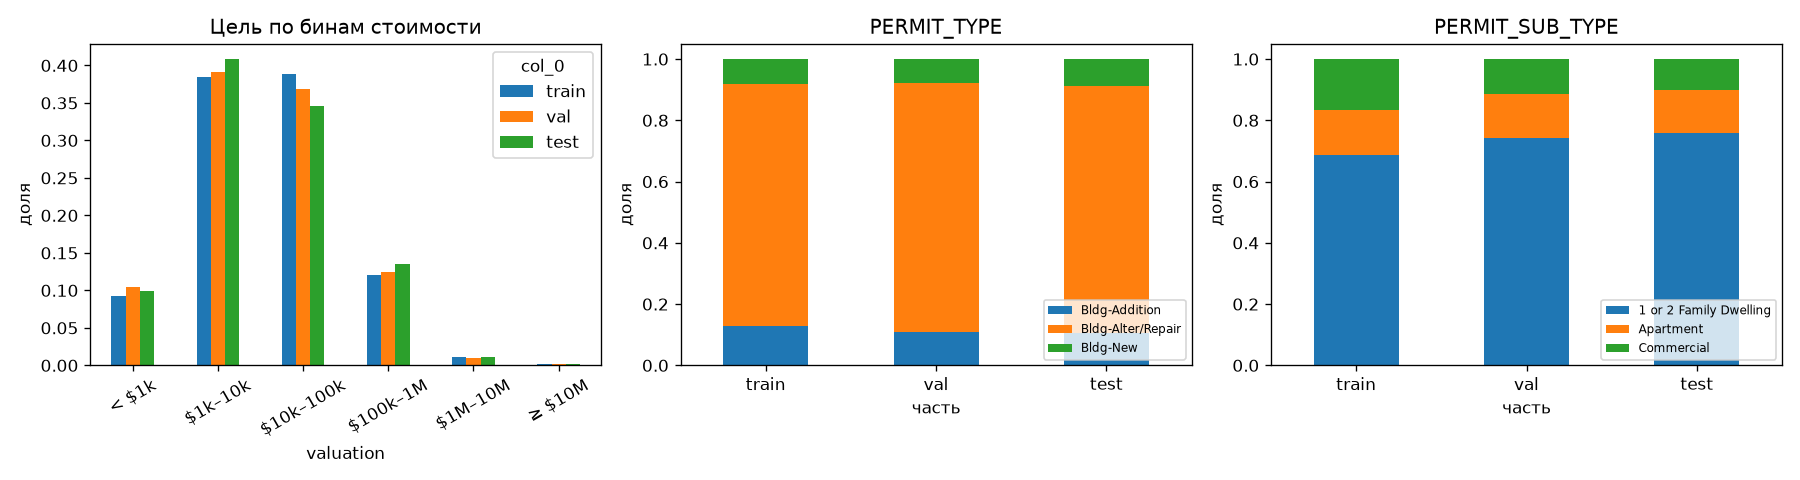

In [10]:
show("balance_target_bins");
show("balance_tail");
show("balance_subgroups_chi2");
img("balance")

**Интерпретация.**
* Распределение по бинам умеренно несбалансировано: нормированная энтропия **0,71**; **imbalance ratio = 201** (train) за счёт редкого хвоста ≥ $10M (0,19% train). В test IR ещё выше (334): дорогих объектов меньше.
* Доля объектов дороже p99 train ($1,31 млн): 1,00% в train, 0,77% в val, 0,90% в test — хвост устойчив, но мал, поэтому качество на дорогих объектах оценивается с большой неопределённостью.
* Состав подгрупп **меняется во времени** (χ², p ≈ 0): доля `Commercial` падает с 16,5% в train до 10,1% в test. Метрики, усреднённые по test, относятся к другому составу, чем train, — это нужно учитывать при сравнении.

## 7. Качество меток

**Метод (confident learning для регрессии).** Для train получены **out-of-fold прогнозы**: 5-fold CV (KFold, seed 42, по всем строкам train), в каждом фолде — FT-Transformer с гиперпараметрами baseline (ранняя остановка по val, как у baseline). Как и baseline, фолдовые модели обучаются и останавливаются **только на строках без R2**, а прогноз делается для всех отложенных строк. Для val и test используются прогнозы baseline (она не видела эти объекты). Остаток $r = \log(1+y) - \hat{y}$; метка считается подозрительной при $|z| > 3{,}5$, где $z = 0{,}6745\,(r - \mathrm{median}\,r)/\mathrm{MAD}(r)$ (Iglewicz–Hoaglin). Медиана и MAD считаются по строкам без R2; служебные строки получают z с тем же порогом и показаны отдельной строкой («среди служебных»), в долю подозрительных не входят.
Дополнительно: доля $|r| > \ln 10$ (ошибка больше чем в 10 раз), `cleanlab.regression` label quality score (метод OUTRE; из-за памяти — 100 соседей вместо 0,5·n), частоты служебных значений и ручной разбор 20 худших.

In [11]:
show("labels_oof_quality");
show("labels_suspicious", cols=["часть", "прогноз", "check", "k", "n", "value", "ci_low", "ci_high"]);

,метрика,value,ci_low,ci_high,ci_method,n
0,RMSLE OOF (train без R2),0.7749,0.7723,0.7776,percentile,459612
1,"MdAPE OOF (train без R2), %",34.29,34.14,34.44,percentile,459612


,часть,прогноз,check,k,n,value,ci_low,ci_high
0,train,OOF 5-fold,|robust z| > 3.5,16384,459612,0.03565,0.03512,0.03619
1,train,OOF 5-fold,|r| > ln 10 (ошибка > 10 раз),7061,459612,0.01536,0.01501,0.01572
2,train,OOF 5-fold,из них прогноз выше метки (метка занижена?),8822,16384,0.5385,0.5308,0.5461
3,train,OOF 5-fold,"|robust z| > 3.5, Bldg-New",380,40908,0.009289,0.008404,0.01027
4,train,OOF 5-fold,"|robust z| > 3.5, Bldg-Addition",1177,62377,0.01887,0.01783,0.01997
5,train,OOF 5-fold,"|robust z| > 3.5, Bldg-Alter/Repair",14827,356327,0.04161,0.04096,0.04227
6,train,OOF 5-fold,служебные оценки R2 (исключены из метрик модели),36984,496596,0.07448,0.07375,0.07521
7,train,OOF 5-fold,|robust z| > 3.5 среди служебных (порог — по строкам без R2),21035,36984,0.5688,0.5637,0.5738
8,val,baseline,|robust z| > 3.5,1382,96451,0.01433,0.0136,0.0151
9,val,baseline,|r| > ln 10 (ошибка > 10 раз),1544,96451,0.01601,0.01524,0.01682


,метрика,value,ci_low,ci_high,ci_method,n
0,"средний label quality score (cleanlab, OOF, train без R2)",0.3782,0.3775,0.3788,percentile,4.596e+05
1,пересечение 16384 худших по cleanlab и по |z|,0.5751,NaN,NaN,NaN,NaN
2,"Spearman(score, −|r|)",0.6605,NaN,NaN,NaN,NaN
3,"доля score < 0,1",0.1258,0.1249,0.1268,wilson,4.596e+05


,check,k,value,ci_low,ci_high,ci_method,n
0,VALUATION = $501,54827,0.0773,0.07668,0.07792,wilson,709309
1,"служебные оценки R2: {$501, $301} ∪ {≤ $10}",56294,0.07936,0.07874,0.08,wilson,709309
2,VALUATION ≤ $100,233,0.0003285,0.0002889,0.0003735,wilson,709309
3,VALUATION кратна $1 000,432626,0.6099,0.6088,0.6111,wilson,709309
4,VALUATION кратна $5 000,269209,0.3795,0.3784,0.3807,wilson,709309
5,"|robust z| > 3.5 среди служебных, train (порог — по строкам без R2)",21035,0.5688,0.5637,0.5738,wilson,36984
6,"|robust z| > 3.5 среди несервисных, train",16384,0.03565,0.03512,0.03619,wilson,459612


,группа,n,median_abs_r_value,median_abs_r_ci_low,median_abs_r_ci_high,median_abs_r_ci_method,median_abs_r_n,susp_value,susp_ci_low,susp_ci_high,susp_ci_method,susp_n
0,близкий дубль в другом фолде,19061,0.1763,0.1725,0.1805,BCa,19061,0.008499,0.007291,0.009905,wilson,19061
1,близкий дубль только в том же фолде,1736,0.2807,0.259,0.3056,BCa,1736,0.02362,0.01746,0.03188,wilson,1736
2,без близкого дубля в train,438815,0.3655,0.3638,0.3673,percentile,438815,0.03687,0.03632,0.03744,wilson,438815


,модель,строки,MAD остатков,"порог |r − median|, log","порог, раз",susp_value,susp_ci_low,susp_ci_high,susp_ci_method,susp_n,susp_prev_abs_thr_value,susp_prev_abs_thr_ci_low,susp_prev_abs_thr_ci_high,susp_prev_abs_thr_ci_method,susp_prev_abs_thr_n,big_value,big_ci_low,big_ci_high,big_ci_method,big_n,доля квадратичной ошибки у подозрительных,jaccard_susp
0,C96 без R2 (текущий baseline),train без R2,0.3546,1.84,6.296,0.03565,0.03512,0.03619,wilson,459612,0.02594,0.02548,0.0264,wilson,4.596e+05,0.01536,0.01501,0.01572,wilson,459612,0.362,0.4295
1,C96 с R2 (прежний baseline),train без R2,0.3772,1.957,7.079,0.03573,0.0352,0.03627,wilson,459612,0.03253,0.03202,0.03305,wilson,4.596e+05,0.0209,0.02049,0.02132,wilson,459612,0.3858,0.4295
2,"C96 с R2 (прежний baseline), прежний отчёт",весь train,0.3881,2.014,7.493,0.03962,0.03908,0.04016,wilson,496596,NaN,NaN,NaN,NaN,NaN,0.02586,0.02542,0.02631,wilson,496596,NaN,NaN


,VALUATION,k,доля
0,501,54827,0.0773
1,5000,29121,0.04106
2,1e+04,27814,0.03921
3,2e+04,22862,0.03223
4,1.5e+04,18786,0.02648
5,3e+04,16381,0.02309
6,3000,16361,0.02307
7,5e+04,15195,0.02142
8,2.5e+04,14446,0.02037
9,2000,13944,0.01966


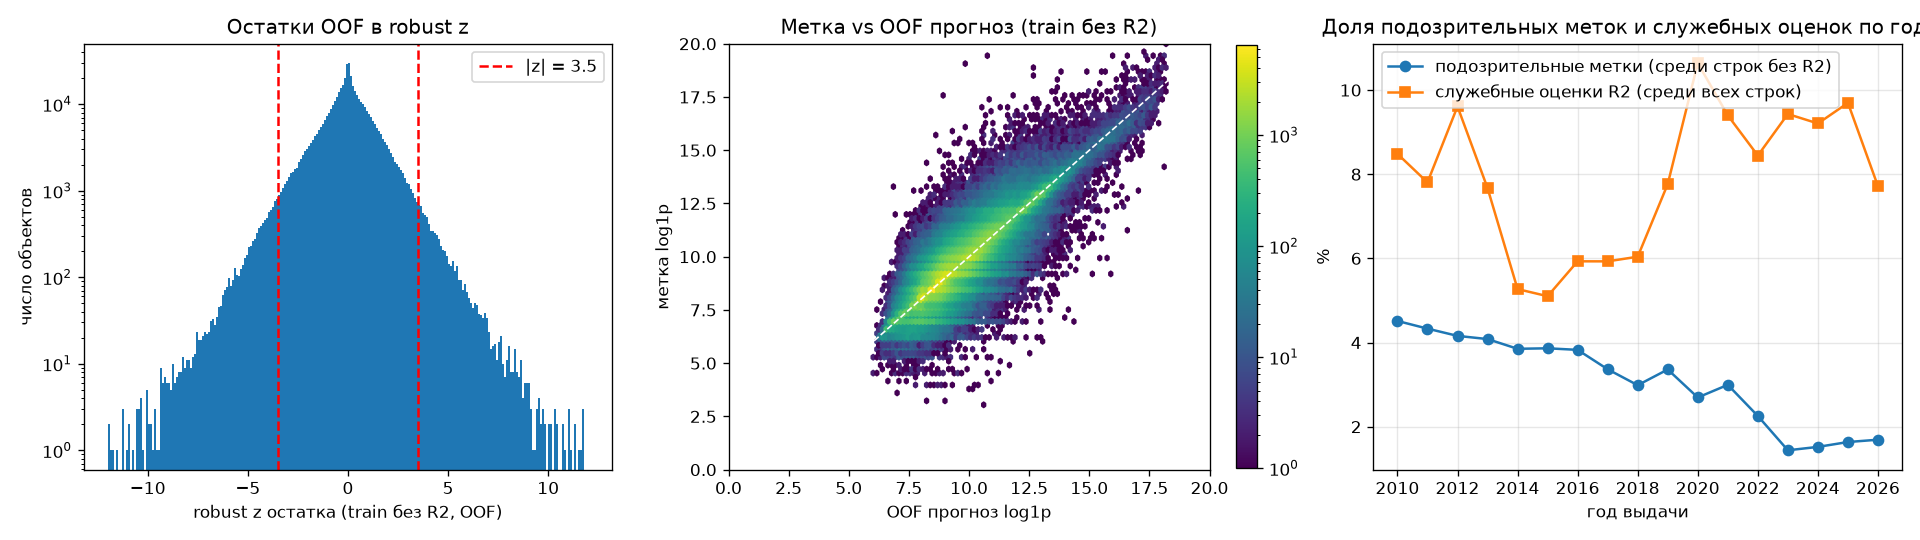

In [12]:
show("labels_cleanlab");
show("labels_service_values");
show("labels_oof_neardup");
show("labels_model_dependence");
show("labels_top_values", n=10);
img("labels")

**Интерпретация.**
* OOF-модель имеет RMSLE **0,775 [0,772; 0,778]** на train без R2 (стратифицированный по типу разрешения bootstrap) — того же уровня, что baseline на val без R2 (0,804), поэтому остатки отражают реальную «предсказуемость» меток. (У прежнего C96 OOF был 0,882, но по всем строкам, включая служебные.)
* **Label error rate = 3,56% [3,51; 3,62]** (train без R2, OOF); в val и test — 1,43% и 1,64%. **1,54%** меток train расходятся с прогнозом больше чем в 10 раз (val 1,60%, test 2,24%). Подозрительные доли val/test ниже, чем у train, потому что разброс остатков прогноза вперёд по времени больше (MAD 0,456 и 0,476 против 0,355 у OOF) и относительный порог выше.
* **Служебные оценки R2** — 7,4% меток train (val 9,4%, test 8,8%). При том же пороге z подозрительны **56,9%** из них против 3,56% у остальных: это и есть причина их исключения.
* **Доля зависит от модели и от совокупности.** Критерий относительный. Без служебных строк MAD остатков меньше (0,355 против 0,388 в прежнем отчёте), поэтому порог |z| > 3,5 соответствует расхождению в 6,3 раза, а не в 7,5. Сравнение на одних строках (train без R2):
  * прежний C96 (обучен со служебными) даёт почти ту же долю подозрительных — 3,57% против 3,56%, но с порогом 7,1 раза;
  * при пороге прежнего отчёта (7,5 раза) подозрительных у нового baseline **2,59%** против 3,25% у прежнего C96, а грубых расхождений (> 10 раз) — 1,54% против 2,09%: исключение R2 улучшило прогноз и на несервисных строках;
  * наборы подозрительных у двух моделей совпадают лишь частично (Jaccard 0,43). Поэтому label error rate — свойство пары «данные + модель», а не только данных; с прежним отчётом (3,96% по всем строкам train) напрямую не сравним.
* Подозрительные метки сосредоточены в `Bldg-Alter/Repair` (4,2%) против 0,9% у `Bldg-New`. У 54% подозрительных прогноз выше метки (метка занижена?).
* **$501 — служебное значение**: 7,7% всех меток (самое частое значение); все служебные оценки R2 — 7,9%. Кроме того, **61% оценок кратны $1 000** (38% — $5 000): оценки округляются, то есть метка заведомо содержит шум квантования.
* **Случайный KFold маскирует часть ошибок меток.** Если близкий дубль строки (тот же участок, похожий текст, стоимость ±10%) попал в другой фолд, OOF-модель фактически видела её метку: медиана |r| у таких строк 0,176 [0,173; 0,180] и подозрительных 0,85%, а у строк, чей дубль оказался в том же фолде (естественный контроль), — 0,281 [0,259; 0,306] и 2,4%. Таких строк 19 061 (4,1% train без R2); если бы доля подозрительных у них была как у контроля, общий label error rate вырос бы примерно на 0,06 п.п. На вывод это не влияет; строгий вариант — GroupKFold по участку.
* cleanlab согласуется с robust z лишь частично (пересечение худших 57,5%, Spearman 0,66): OUTRE учитывает и величину самой метки, поэтому помечает также крайние, но правдоподобные значения. Основным критерием остаётся robust z (как и было решено).

In [13]:
show("labels_worst20", cols=["PERMIT_NBR", "PERMIT_TYPE", "SUB_TYPE", "SQUARE_FOOTAGE", "VALUATION", "OOF прогноз $", "z", "WORK_DESC"]);
show("labels_prev_worst20");


,PERMIT_NBR,PERMIT_TYPE,SUB_TYPE,SQUARE_FOOTAGE,VALUATION,OOF прогноз $,z,WORK_DESC
0,12010-10007-01270,Bldg-Alter/Repair,Commercial,NaN,1.911e+08,1.851e+04,17.57,"Structural frame erection permit to construct core and shell of structural framing from ground floor to 26th floor (elev. =586'-0"") of t..."
1,10010-10002-01204,Bldg-Alter/Repair,Apartment,NaN,4.511e+07,6953,16.69,"Early start (FOUNDATION ONLY) for A PROPOSED MIXED USE RESIDENTIAL, RETAIL, PARKING BLDG. 915 UNITS 1,074,488 SF (TYPE IIIA CONST), 33,..."
2,17010-10008-01465,Bldg-Alter/Repair,Commercial,NaN,2.625e+08,4.574e+04,16.46,"SUPPLEMENTAL TO PERMIT #17010-10000-01465 FOR EARLY START PERMIT BETWEEN TOP OF ISOLATOR COLUMNS, GROUND LEVEL SLAB THROUGH LEVEL 2 SLAB..."
3,16016-20000-02974,Bldg-Alter/Repair,1 or 2 Family Dwelling,NaN,20,3.963e+04,-14.36,"Kitchen, (3) bathroom remodel for residential buildings (no structural changes). (21) Window and (3) door change-out (same size & type) ..."
4,18016-30000-13835,Bldg-Addition,Commercial,2.297e+04,990,1.855e+06,-14.34,"EXPAND EXISTING MAZZANINE, AND ENCLOSE EXISTING COVERED LOADING DOCK IN EXISTING SOUND SCORE PRODUCTION FACILITY WITH NO RECORDING STUDIO."
5,13010-10000-00494,Bldg-New,1 or 2 Family Dwelling,3650,394.6,5.027e+05,-13.6,NEW 2-STORY DUPLEX WITH ATTACHED 2-CAR GARAGE. FULLY SPRINKLERED WITH NFPA-13D
6,16010-10002-05912,Bldg-Alter/Repair,Apartment,NaN,6.44e+06,5673,13.37,SUPP. PERMIT TO CAPTURE CORRECT CINSTRUCTION COST
7,17010-10000-05141,Bldg-New,1 or 2 Family Dwelling,2170,243,2.67e+05,-13.32,NEW 2-STORY DUPLEX BUILDING (2) WITH ATTACHED ONE CAR GARAGE. BUILDING MUST BE EQUIPPED WITH AUTOMATIC SPRINKLER SYSTEM PER NFPA 13D.
8,20010-70000-00880,Bldg-New,1 or 2 Family Dwelling,1.195e+04,1227,1.17e+06,-13.06,NEW 4-STORY DUPLEX AND 2-CAR GARAGE
9,18010-30000-01725,Bldg-New,1 or 2 Family Dwelling,1200,145,1.253e+05,-12.86,NEW ADU WITH ATTACHED 2-CAR GARAGE AT REAR OF THE LOT PER AB 494 AND SB 229


,PERMIT_NBR,VALUATION,служебная (R2),прогноз C96 с R2 (прежний baseline) $,прогноз C96 без R2 (текущий baseline) $,новый / прежний,z прежний,z новый,WORK_DESC
0,17010-10008-01465,2.625e+08,False,587,4.574e+04,77.89,22.57,16.46,"SUPPLEMENTAL TO PERMIT #17010-10000-01465 FOR EARLY START PERMIT BETWEEN TOP OF ISOLATOR COLUMNS, GROUND LEVEL SLAB THRO"
1,09014-10001-01473,2.55e+08,False,2639,8.294e+06,3143,19.91,6.509,Foundation/frame only permit for 09014-10000-01473. Original work description: North and south concourse addition to ex
2,10010-10000-02362,501,True,2.426e+07,4.43e+07,1.826,-18.79,-21.67,"NEW CENTRAL UTILITY PLANT FOR LAX , TYPE I-B CONSTRUCTION, 4 STORY, 47,930 SF"
3,12010-10002-00465,501,True,1.113e+07,7.332e+06,0.659,-17.43,-18.25,"3 LEVELS PARKING STRUCTURE WITH BASKETBALL COURT, TOILET ROOMS, STORAGE AND METAL TRELLIS ABOVE AT 4TH LEVEL. See 12010-"
4,19010-10000-02232,501,True,1.016e+07,1.137e+07,1.119,-17.27,-19.08,NEW CONSTRUCTION OF LAX AIRPORT POLICE DIVISION SHOOTING RANGE BUILDING W/ ATTACHED PARKING STRUCTURE ACCOMODATING SITE
5,13010-10005-03498,501,True,1.005e+07,1.57e+06,0.1562,-17.25,-15.32,SUPPLEMENTAL PERMIT TO EARLY START FOUNDATION PLUS PERMIT 13010-10002-03498: MODIFY FOUNDATION ALONG THE WEST PERIMETER
6,05010-10006-05187,501,True,8.234e+06,1.12e+06,0.1361,-16.91,-14.68,"TO CORRECT PERMIT NUMBER 05010-1000-05187 WORK DESCRIPTION TO ""NEW 21-STORY CONDO BUILDING CORE AND SHELL ONLY. PERMIT"
7,12010-10007-01270,1.911e+08,False,1.325e+04,1.851e+04,1.397,16.6,17.57,Structural frame erection permit to construct core and shell of structural framing from ground floor to 26th floor (elev
8,11010-10000-00257,501,True,5.526e+06,1.917e+07,3.469,-16.21,-20.08,NEW REPLACEMENT MAINTENANCE BUILDING (WITH HVAC COOLING TOWERS) FOR LAX CTA CENTRAL UTILITY PLANT (CUP) PROJECT.
9,15010-10002-00387,2.064e+07,False,2058,1.688e+06,820.2,15.97,4.755,PROPOSED FOUNDATION ONLY PERMIT FOR A 6 STORY 370 UNIT APARTMENT WITH GARAGE (INCLUDES 101 JOINT LIVE/WORK UNITS) TIE


**Ручной разбор 20 худших меток (train без R2).** Служебные суммы из списка ушли по построению, и наверх вышли другие практики оформления:

| Категория | Строки таблицы (сверху вниз) | Кол-во | Что видно |
|---|---|---|---|
| Стоимость, похоже, указана в тысячах долларов | 4, 5, 6, 8, 9, 10, 11, 13, 14, 15, 20 | 11 | Новые дома и дуплексы на 1 200–11 946 кв. футов за $145–1 227, пристройка 22 971 кв. футов за $990, мелкие пристройки за $51–97, ремонт кухни, трёх ванных и замена 24 окон и дверей за $20; прогноз в 650–2 000 раз выше метки, то есть метка × 1 000 правдоподобна |
| Стоимость всего проекта на дополнительном разрешении | 7 | 1 | «Supp. permit to capture correct construction cost» — $6,4 млн |
| Неоднозначно | 12, 16, 17 | 3 | Supplemental с изменением числа квартир ($10 000), смена назначения на 216 мест ($2 000) — возможно, тоже в тысячах; частичный снос и усиление коммерческого здания, shell only ($37,5 млн) — возможно, стоимость этапа, возможно, всего проекта |
| Правдоподобная метка, ошибка модели | 1, 2, 3, 18, 19 | 5 | Этапные разрешения крупных объектов (каркас 26-этажного отеля, фундамент жилого комплекса на 915 квартир, музей, фундамент 21-этажного дома, сваи дома на 306 квартир) на $8–262 млн, оформленные как Alter/Repair без площади: слова «supplemental», «early start», «foundation only» обычно означают дешёвое разрешение, и модель прогнозирует $7–46 тыс. |

Итого **12 из 20** — проблемы метки, **3** — неоднозначно, **5** — пределы модели (в прежнем отчёте на всех строках — тоже 12 / 3 / 5, но 11 из 12 проблем там были служебными суммами $1 и $301–501).
«Стоимость в тысячах» — редкая практика: прогноз в 300–3 000 раз выше метки только у 26 строк train без R2 (0,006%), и все они в списке подозрительных. Отдельное правило очистки ради них не нужно.
Из прежних 20 худших 11 — служебные оценки R2 (теперь исключены), в новом списке 2. Остальные 9 по-прежнему подозрительны (|z| от 4,8 до 17,6): у части из них прогноз вырос в 16–3 100 раз (модель, обученная без $501, реже прогнозирует копейки для «early start» и «foundation only»), но до метки всё ещё далеко (вторая таблица выше).
Вывод не меняется: основная часть «шума меток» — не случайные опечатки, а **систематические практики оформления** (служебные суммы, стоимость в тысячах, перенос стоимости проекта на дополнительное разрешение, этапные разрешения без площади).

## 8. Репрезентативность и сдвиг распределений (train vs test)

* **MMD** (RBF, медианная эвристика; несмещённая U-статистика) на подвыборках по 5 000 объектов: permutation p-value (1 000 перестановок) и стратифицированный bootstrap CI (B = 2000). Представления: признаки без времени; признаки со временем; эмбеддинги [CLS] baseline-модели. **Контроль** — две случайные половины train.
* **C2ST**: классификатор (логистическая регрессия и MLP) отличает train от test; ROC-AUC на отложенной половине (20 000 + 20 000), BCa-интервал со стратификацией по классу. 0,5 — неразличимы.
* KS-тест для цели и динамика по годам.

,сравнение,представление,mmd2_u,ci_low,ci_high,p_value,perm_q95
0,train vs test,признаки без времени,0.02201,0.02035,0.02381,0.000999,6.223e-05
1,train vs test,признаки с временем,0.03113,0.02955,0.03287,0.000999,5.96e-05
2,train vs test,эмбеддинги [CLS] baseline,0.008865,0.007806,0.009958,0.000999,0.000191
3,train vs val,признаки без времени,0.01686,0.01548,0.0184,0.000999,5.724e-05
4,train vs val,признаки с временем,0.02616,0.02481,0.02765,0.000999,5.332e-05
5,train vs val,эмбеддинги [CLS] baseline,0.005775,0.004977,0.006733,0.000999,0.0001856
6,train_A vs train_B,признаки без времени,3.481e-05,-4.568e-05,0.0001282,0.09391,4.496e-05
7,train_A vs train_B,признаки с временем,2.813e-05,-4.817e-05,0.000118,0.1349,4.388e-05
8,train_A vs train_B,эмбеддинги [CLS] baseline,-8.345e-06,-0.0001974,0.0003587,0.4196,0.00021
9,val vs test,признаки без времени,0.001354,0.0009949,0.001802,0.000999,9.206e-05


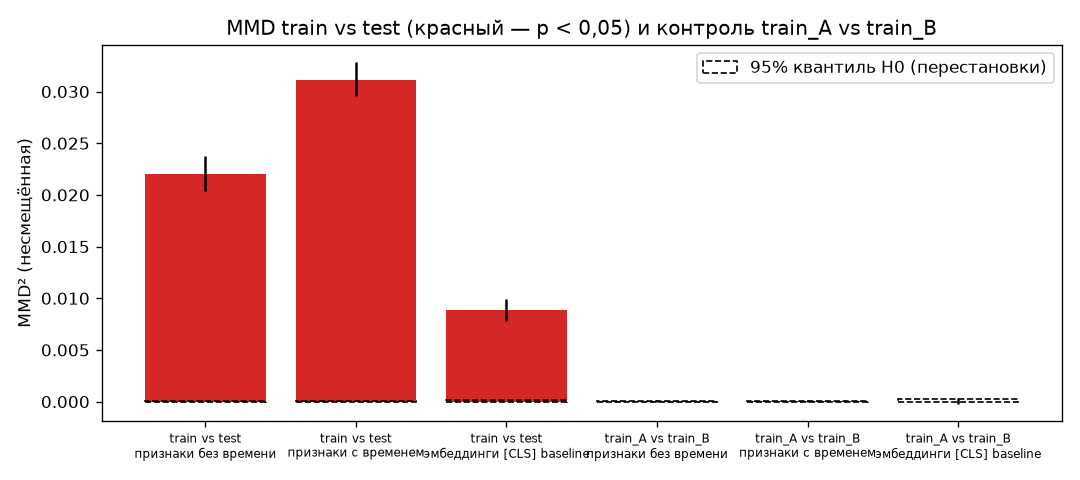

,сравнение,время,классификатор,auc,auc_ci_low,auc_ci_high,accuracy
0,train vs test,нет,логистическая регрессия,0.8932,0.8891,0.8975,0.8095
1,train vs test,нет,MLP (64),0.9216,0.9181,0.9251,0.8383
2,train vs test,да,логистическая регрессия,0.9929,0.9918,0.9938,0.9786
3,train vs test,да,MLP (64),0.9899,0.9885,0.9911,0.9667
4,train vs val,нет,логистическая регрессия,0.826,0.82,0.8316,0.7476
5,train vs val,нет,MLP (64),0.8644,0.8593,0.8692,0.7795
6,train vs val,да,логистическая регрессия,0.9902,0.9889,0.9913,0.9744
7,train vs val,да,MLP (64),0.985,0.9833,0.9866,0.9613
8,train_A vs train_B,нет,логистическая регрессия,0.5008,0.493,0.5091,0.5017
9,train_A vs train_B,нет,MLP (64),0.503,0.4949,0.5113,0.4994


In [14]:
show("shift_mmd", cols=["сравнение", "представление", "mmd2_u", "ci_low", "ci_high", "p_value", "perm_q95"]);
img("shift_mmd")
show("shift_c2st", cols=["сравнение", "время", "классификатор", "auc", "auc_ci_low", "auc_ci_high", "accuracy"]);

**Интерпретация MMD и C2ST.**
* Контроль работает: две случайные половины train неразличимы (MMD² ≈ 0, p = 0,09–0,42; C2ST AUC 0,50 [0,49; 0,51]).
* **Train и test различимы очень сильно**: MMD²_u = 0,022 [0,020; 0,024] при 95%-м квантиле нулевого распределения 0,0001 (p ≤ 0,001); C2ST без признаков времени — **ROC-AUC 0,89 [0,89; 0,90]** (логрег) и **0,92 [0,92; 0,93]** (MLP). С признаками времени AUC ≈ 0,99 — это тривиально: год выдачи отличается по построению split.
* Даже соседний по времени val отличается от train (AUC 0,83–0,86).
* В пространстве эмбеддингов [CLS] baseline сдвиг train vs test тоже значим: MMD² 0,0089 [0,0078; 0,0100], p ≤ 0,001 (у прежнего C96 — 0,0045: другая модель — другое пространство эмбеддингов). **Интерпретировать его как сдвиг данных нельзя:** объекты train — обучающие для модели, поэтому различие смешивает сдвиг с подгонкой модели под train, а контроль train_A vs train_B этого не ловит (обе половины тоже из обучения). Сравнивать величину MMD² с признаковым представлением тоже нельзя: ядра и ширины разные.
* Части, которые модель не видела, сравнимы корректно: **val vs test** различаются и в признаках (MMD² 0,0014 [0,0010; 0,0018]), и в [CLS] (0,0010 [0,0006; 0,0014]), p ≤ 0,001 — сдвиг продолжается и после окончания train.

Какие признаки дают сдвиг — C2ST по каждой группе признаков отдельно:

,группа признаков,value,ci_low,ci_high,ci_method
0,число: issue_year,0.9736,0.9714,0.9758,BCa
1,текст: SVD(64),0.8645,0.8598,0.8692,BCa
2,категория: CNC,0.7393,0.7322,0.7457,BCa
3,категория: CT,0.6866,0.6794,0.6934,BCa
4,категория: ZONE,0.6312,0.6232,0.6387,BCa
5,число: desc_len,0.6178,0.6099,0.6254,BCa
6,категория: Business Unit,0.6163,0.6091,0.6235,BCa
7,категория: USE_DESC,0.5809,0.5743,0.5884,BCa
8,категория: zone_base,0.5697,0.562,0.5773,BCa
9,категория: TYPE_LAT_LON,0.5663,0.5617,0.5712,BCa


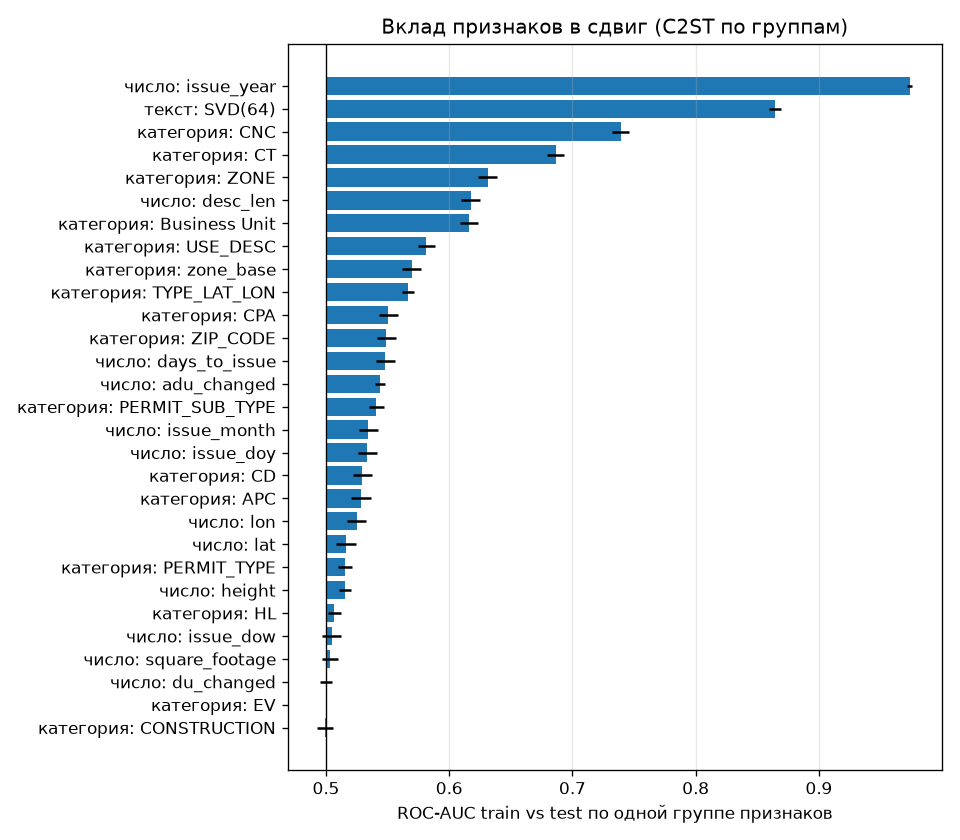

,check,часть,value,ci_low,ci_high
0,текст: «Eplan» (электронная подача),train,0.008655,0.008401,0.008916
1,текст: «Eplan» (электронная подача),val,0.1428,0.1407,0.1449
2,текст: «Eplan» (электронная подача),test,0.1851,0.1828,0.1875
3,текст: номер другого разрешения в тексте,train,0.108,0.1071,0.1089
4,текст: номер другого разрешения в тексте,val,0.1397,0.1376,0.1418
5,текст: номер другого разрешения в тексте,test,0.1473,0.1452,0.1494
6,текст: «supplement»,train,0.09863,0.09781,0.09946
7,текст: «supplement»,val,0.1193,0.1174,0.1213
8,текст: «supplement»,test,0.133,0.131,0.1351
9,текст: шаблон re-roof «Class A or B»,train,0.1465,0.1456,0.1475


In [15]:
show("shift_feature_c2st", cols=["группа признаков", "value", "ci_low", "ci_high", "ci_method"], n=12);
img("shift_feature_c2st", width=700)
show("shift_drift_facts", cols=["check", "часть", "value", "ci_low", "ci_high"]);

**Причины сдвига** (кроме года выдачи, AUC 0,97):
1. **Текст (AUC 0,86)** — меняется практика оформления: префикс «Eplan» (электронная подача) встречается у 0,9% train и **18,5% test**; шаблон описания перекрытия кровли «Class A or B» — 14,7% → 25,8%; ADU (дополнительные жилые единицы после изменения законов штата) — 4,8% → 13,7%; ссылки на другие разрешения — 10,8% → 14,7%, supplemental — 9,9% → 13,3%.
2. **Административная география**: **13,7% test-объектов имеют census tract, которого нет в train** (новая сетка после переписи 2020 г.), **23,4% — название районного совета (CNC), которого нет в train** (переименования). Для модели это категория `OTHER`.
3. Слабее — зона, длина описания, тип рассмотрения (Business Unit), назначение (USE_DESC).

Структурные признаки (площадь, высота, число квартир, тип конструкции) почти не сдвинуты (AUC ≈ 0,50).

,сравнение,KS D,p_value,медиана log1p a,медиана log1p b
0,train vs val,0.02443,7.362e-46,9.21,9.21
1,train vs test,0.03404,1.491e-88,9.21,9.17
2,val vs test,0.01287,4.449e-08,9.21,9.17


,год,n,медиана $,p25 $,p75 $,доля $501,доля Alter/Repair,доля Commercial,доля Supplemental,пропуск площади
0,2010,30654,8500,3000,3e+04,0.07059,0.7995,0.2017,0.1059,0.7354
1,2011,31410,8000,3000,2.632e+04,0.06909,0.8165,0.202,0.09195,0.7541
2,2012,32805,8600,3000,3e+04,0.09114,0.8076,0.202,0.1016,0.7407
3,2013,33959,9840,3413,3.5e+04,0.07444,0.7905,0.1967,0.09255,0.7335
4,2014,33717,1e+04,4000,4.1e+04,0.05152,0.7608,0.1924,0.07972,0.7082
5,2015,37698,1e+04,4400,4e+04,0.04915,0.7649,0.1889,0.08008,0.7192
6,2016,39456,1e+04,4000,4e+04,0.05746,0.7703,0.1693,0.08893,0.7276
7,2017,46194,1e+04,4400,4e+04,0.05726,0.7833,0.1623,0.08858,0.7193
8,2018,48939,1.26e+04,4500,4.5e+04,0.05918,0.7783,0.1426,0.09487,0.7043
9,2019,51569,1.2e+04,4200,4e+04,0.07677,0.7941,0.1451,0.1146,0.7188


,год,часть,прогноз,n,value,ci_low,ci_high,ci_method
0,2010,train,OOF 5-fold,28053,0.8532,0.8424,0.8646,BCa
1,2011,train,OOF 5-fold,28958,0.8306,0.8211,0.8412,BCa
2,2012,train,OOF 5-fold,29652,0.8241,0.8141,0.8341,BCa
3,2013,train,OOF 5-fold,31354,0.821,0.8115,0.8314,BCa
4,2014,train,OOF 5-fold,31940,0.8126,0.8032,0.8234,BCa
5,2015,train,OOF 5-fold,35775,0.8059,0.7966,0.8164,BCa
6,2016,train,OOF 5-fold,37116,0.7954,0.7864,0.8053,BCa
7,2017,train,OOF 5-fold,43455,0.7611,0.7526,0.7697,BCa
8,2018,train,OOF 5-fold,45983,0.742,0.7333,0.7511,BCa
9,2019,train,OOF 5-fold,47564,0.7438,0.7362,0.7517,BCa


,год,доля UNK среди слов,"средняя длина, слов",обрезано на 96 словах,n
0,2010,0.008032,22.73,0.002284,30654
1,2011,0.007868,22.08,0.001687,31410
2,2012,0.007789,23.41,0.001128,32805
3,2013,0.007017,22.67,0.001443,33959
4,2014,0.006518,22.34,0.001305,33717
5,2015,0.005009,28.35,0.005199,37698
6,2016,0.004326,29.34,0.005373,39456
7,2017,0.0041,31.17,0.008053,46194
8,2018,0.004221,29.58,0.006804,48939
9,2019,0.004471,30.82,0.006787,51569


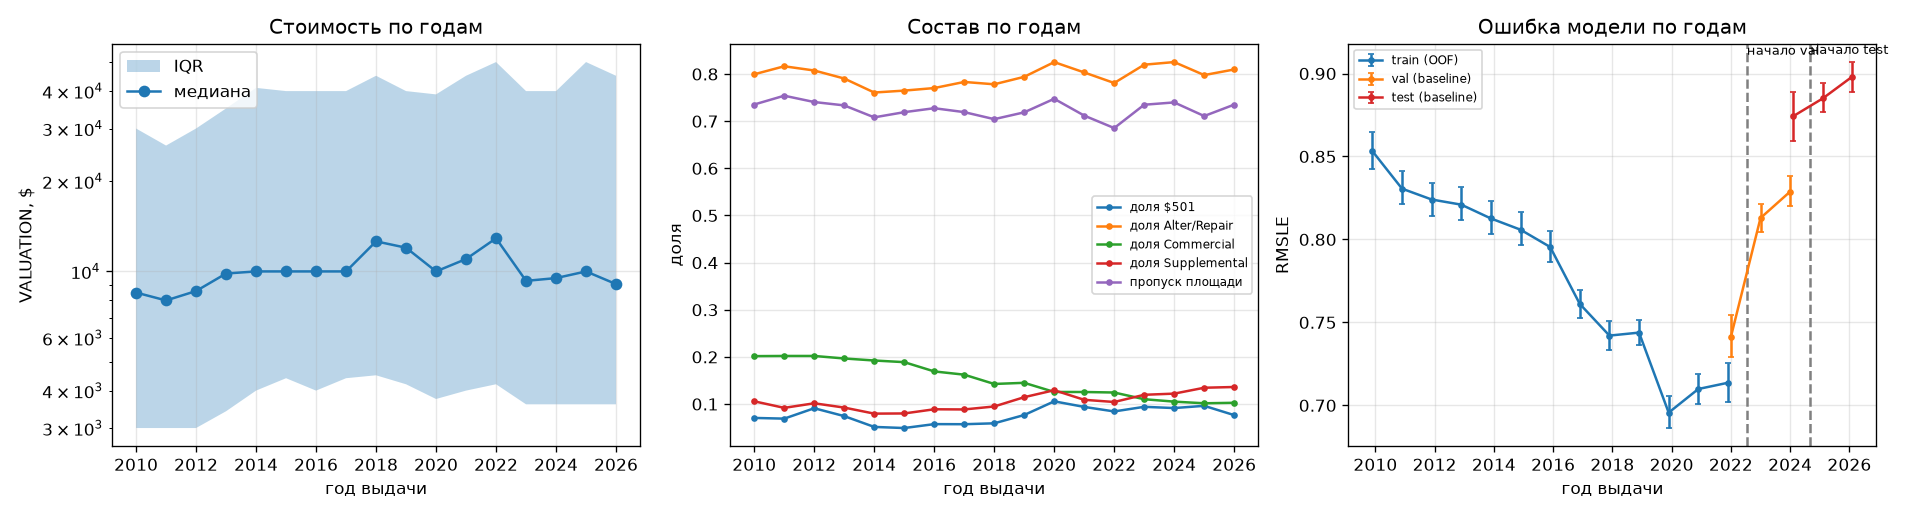

In [16]:
show("shift_ks_target");
show("shift_by_year");
show("shift_error_by_year");
show("shift_text_vocab_by_year");
img("shift_by_year")

**Сдвиг цели и динамика.**
* Распределение цели меняется слабо: KS D = 0,034 между train и test (значимо при таком n, но медиана log-стоимости почти та же: 9,21 → 9,17).
* По годам: доля `Commercial` монотонно падает (20% → 10%), доли $501 и дополнительных разрешений растут с 2019–2020 гг.
* Ошибка модели по годам (строки без R2, bootstrap CI в таблице): OOF на train снижается от 0,853 (2010) до 0,696–0,714 (2020–2022); на val и test **растёт до 0,885 [0,877; 0,895] и 0,898 [0,889; 0,907] (2025–2026)**. Это не чистый эффект сдвига: для train ошибка считается по OOF со случайными фолдами внутри периода (интерполяция), для val/test — прогнозом вперёд по времени. Величину разрыва методов видно в 2022 г., где есть обе части: OOF на train 0,714 [0,702; 0,726], прогноз на val 0,741 [0,729; 0,755]. Рост ошибки от val к test (0,813 в 2023 г. → 0,874–0,898) уже не связан с методом и отражает сдвиг. Во всех годах ошибка на 0,08–0,15 ниже, чем у прежнего C96 по всем строкам: сказываются и исключение служебных строк из оценки, и лучшая модель.
* Словарь слов-токенов собран по train и со временем «стареет»: доля незнакомых слов (UNK) растёт с 0,56% в 2022 г. до 1,36% в 2026 г., средняя длина описания — с 32 до 40 слов, доля описаний длиннее 96 слов (хвост обрезается) — с 0,6% до 2,2%.

## 9. Аномалии

* **Критерий 1 — IsolationForest** (300 деревьев, обучен на 200 000 объектов train, признаки без времени): объект аномален, если его score ниже 1-го перцентиля train (в train таких по определению 1%). Дополнительно — встроенный порог `contamination="auto"`.
* **Критерий 2 — выброс цели**: |robust z| > 3,5 для log1p(VALUATION) (медиана и MAD по train).

,часть,check,k,n,value,ci_low,ci_high
0,train,IsolationForest: score ≤ 1-й перцентиль train,4966,496596,0.01,0.009727,0.01028
1,train,IsolationForest: contamination='auto',2995,496596,0.006031,0.00582,0.00625
2,train,"выброс log-цели (|robust z| > 3.5, медиана/MAD train)",2350,496596,0.004732,0.004545,0.004927
3,val,IsolationForest: score ≤ 1-й перцентиль train,2082,106421,0.01956,0.01875,0.02041
4,val,IsolationForest: contamination='auto',1157,106421,0.01087,0.01027,0.01151
5,val,"выброс log-цели (|robust z| > 3.5, медиана/MAD train)",370,106421,0.003477,0.003141,0.003849
6,test,IsolationForest: score ≤ 1-й перцентиль train,1953,106292,0.01837,0.01758,0.0192
7,test,IsolationForest: contamination='auto',1140,106292,0.01073,0.01012,0.01136
8,test,"выброс log-цели (|robust z| > 3.5, медиана/MAD train)",449,106292,0.004224,0.003852,0.004632


,группа test,rmsle,ci_low,ci_high,ci_method,n
0,аномалии IsolationForest,0.5257,0.4965,0.5721,BCa,1949
1,остальные,0.8944,0.8885,0.9001,percentile,95003


,часть,группа,check,k,n,value,ci_low,ci_high
0,train,аномалии,PERMIT_TYPE = Bldg-Addition,1450,4966,0.292,0.2795,0.3048
1,train,остальные,PERMIT_TYPE = Bldg-Addition,61564,491630,0.1252,0.1243,0.1262
2,train,аномалии,PERMIT_TYPE = Bldg-Alter/Repair,379,4966,0.07632,0.06926,0.08404
3,train,остальные,PERMIT_TYPE = Bldg-Alter/Repair,392128,491630,0.7976,0.7965,0.7987
4,train,аномалии,PERMIT_TYPE = Bldg-New,3137,4966,0.6317,0.6182,0.645
5,train,остальные,PERMIT_TYPE = Bldg-New,37938,491630,0.07717,0.07643,0.07792
6,train,аномалии,ADU в описании работ,1836,4966,0.3697,0.3564,0.3832
7,train,остальные,ADU в описании работ,22124,491630,0.045,0.04443,0.04558
8,train,аномалии,площадь заполнена,4932,4966,0.9932,0.9904,0.9951
9,train,остальные,площадь заполнена,132454,491630,0.2694,0.2682,0.2707


,PERMIT_TYPE,группа test,rmsle,ci_low,ci_high,ci_method,n
0,Bldg-Addition,аномалии IsolationForest,0.5743,0.5324,0.6449,BCa,832
1,Bldg-Addition,остальные,0.7038,0.689,0.7197,BCa,10106
2,Bldg-Alter/Repair,аномалии IsolationForest,0.667,0.5983,0.7492,BCa,182
3,Bldg-Alter/Repair,остальные,0.943,0.9367,0.9493,percentile,76440
4,Bldg-New,аномалии IsolationForest,0.4426,0.3997,0.5489,BCa,935
5,Bldg-New,остальные,0.5976,0.5729,0.6347,BCa,8457


,PERMIT_NBR,PERMIT_TYPE,USE_DESC,SQUARE_FOOTAGE,HEIGHT,DU_CHANGED,VALUATION,score,WORK_DESC
0,16010-40000-05282,Bldg-New,Apartment,1.384e+04,42,8,1.5e+06,-0.5545,New 4 story 8 unit apartment building with attached parking garage.
1,20014-10000-04451,Bldg-Addition,Duplex,2502,23,0,3e+04,-0.5444,(N) ACCESSORY DWELLING UNIT ADDITION TO (E) 2-STORY SINGLE FAMILY DWELLING PER LAMC 12.22 A.33
2,21014-20000-01759,Bldg-Addition,Accessory Dwelling Unit,480,NaN,NaN,5.5e+04,-0.5426,PROPOSED 12' X 40' ADDITION TO (E) DETACHED GARAGE FOR (N) ACCESSORY DWELLING UNIT PER LAMC 12.22 A.33(c) AND (d). ALL WORK PER WFPP.
3,19014-40000-01515,Bldg-Addition,Dwelling - Single Family,1653,12.75,0,5e+04,-0.5422,Remodel and addition to (E) single family dwelling with attached garage.
4,17010-10000-02063,Bldg-New,Accessory Dwelling Unit,800,12,NaN,8.4e+04,-0.5391,PROPOSED ACCESSORY DWELLING UNIT PER AB 494 AND SB 229
5,20010-30000-04471,Bldg-New,Accessory Dwelling Unit,4148,38,2,4e+05,-0.5386,NEW 3-STORY DUPLEX WITH ATTACHED GARAGE AND ATTACHED ADU
6,19010-10000-05047,Bldg-New,Accessory Dwelling Unit,583,12.75,NaN,7.4e+04,-0.5377,PROPOSED DETACHED ACCESSORY DWELLING UNIT PER AB 494 AND SB 229.
7,21014-10000-05465,Bldg-Addition,Accessory Dwelling Unit,758,11.75,NaN,6.12e+04,-0.5376,ADDITION TO (E) DETACHED GARAGE TO BE CONVERT TO ADU PER LAMC 12.22 A.33(c) AND (d)
8,19010-20000-00124,Bldg-New,Duplex,1996,36.08,2,3.2e+05,-0.5366,(N) 3-STORY DUPLEX W/ ATTACHED GARAGE (NFPA-13D FIRE SPRINKLERS THROUGHOUT)
9,19010-20000-00125,Bldg-New,Duplex,1996,34,2,3.2e+05,-0.5366,(N) 3-STORY DUPLEX W/ ATTACHED GARAGE (NFPA-13D FIRE SPRINKLERS THROUGHOUT)


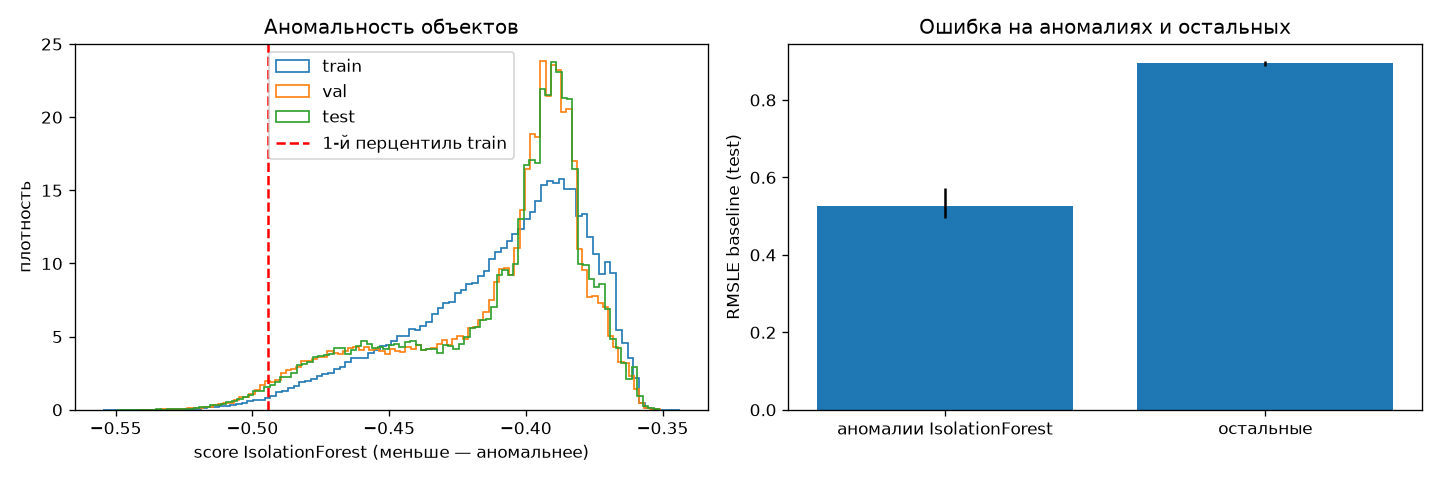

In [17]:
show("anomalies", cols=["часть", "check", "k", "n", "value", "ci_low", "ci_high"]);
show("anomalies_error");
show("anomalies_profile", cols=["часть", "группа", "check", "k", "n", "value", "ci_low", "ci_high"]);
show("anomalies_error_by_type");
show("anomalies_top15", n=10);
img("anomalies")

**Интерпретация.**
* В test **1,84% [1,76; 1,92]** объектов аномальны по критерию train (ожидалось 1% при отсутствии сдвига) — ещё одно подтверждение сдвига.
* Выбросы цели редки: 0,42% в test (очень дешёвые и очень дорогие работы).
* **Кто аномален.** Аномалии — почти только разрешения `Bldg-New` и `Bldg-Addition` (в test 48,0% и 42,6% аномалий против 8,2% и 9,8% среди остальных) с заполненными структурными полями: площадь заполнена у 99,7% аномалий против 26,1% остальных. У основной массы данных (`Alter/Repair`) площадь, высота и конструкция пусты, поэтому объект с полным набором структурных признаков оказывается «изолированным». Чаще всего это **ADU** (дополнительные жилые блоки): ADU упоминается в описании у 81,6% аномалий test против 12,4% остальных; среди строк с ADU аномальны 10,9%, без ADU — 0,39%.
* **Почему аномалий в test больше:** доля ADU в текстах выросла с 4,8% в train до 13,7% в test (раздел 8), а ADU — самый частый вид аномалии.
* **На аномалиях ошибка модели ниже:** RMSLE 0,53 [0,50; 0,57] против 0,89 (test без R2). Частично это состав — New и Addition предсказываются лучше, чем Alter/Repair, — но эффект сохраняется и внутри каждого типа: New 0,44 [0,40; 0,55] против 0,60, Addition 0,57 [0,53; 0,64] против 0,70, Alter/Repair 0,67 [0,60; 0,75] против 0,94. Заполненные структурные поля дают модели больше информации. Аномальность в пространстве признаков ≠ трудность для модели; трудные объекты определяются качеством меток (раздел 7).
* *Исправление (03.11.2026):* в прежней версии таблица топ-15 аномалий строилась по сдвинутым индексам и показывала обычные объекты (шаблонные тексты перекрытия кровли, замены окон), отсюда ошибочный вывод о «шаблонных текстах». Доли аномалий и ошибка на них считались по верной маске и не изменились.

## 10. Итоговая таблица (формат методички)

In [18]:
summary = pd.read_csv(R / "summary.csv")
display(summary)

,Свойство,Метрика,Значение,95% CI,Метод CI,Интерпретация
0,Полнота,доля пропущенных ячеек (используемые признаки),23.71,[23.69; 23.72],percentile,"в %; пропуски в основном структурные (площадь, высота, конструкция заполняются для New/Addition)"
1,Полнота,доля объектов с ≥ 1 пропуском (используемые признаки),99.94,[99.93; 99.94],wilson,в %; почти у каждого объекта есть пропуск → модель должна работать с пропусками (эмбеддинг «пропуск»)
2,Полнота,пропуск площади у Bldg-New,2.09,[1.97; 2.20],wilson,в %; для нового строительства площадь почти всегда заполнена
3,Валидность,доля объектов с ≥ 1 нарушением формата/диапазона/правил,14.04,[13.96; 14.12],wilson,в %; основной вклад — VALUATION ≤ 0 и нулевая площадь
4,Валидность,VALUATION ≤ 0 (невалидная метка),6.64,[6.59; 6.70],wilson,в %; строки исключены из обучения
5,Валидность,SQUARE_FOOTAGE ≤ 0 среди заполненных,16.33,[16.16; 16.49],wilson,в %; ноль используется как «не указано» — шум в важном признаке
6,Уникальность,duplicate rate (дубли без учёта ID),0.061,[0.056; 0.067],wilson,в %; точных дублей нет (PERMIT_NBR уникален); дубли удалены до split
7,Уникальность,"near-duplicate rate (APN + MinHash Jaccard ≥ 0,9 + стоимость ±10%)",2.96,[2.92; 3.00],wilson,в %; в основном однотипные разрешения на разные объекты одного участка; только полные APN — 2.25%
8,Уникальность,доля дополнительных разрешений (Supplemental),10.69,[10.62; 10.76],wilson,"в %; связаны с основным разрешением, стоимость часто служебная ($501)"
9,Train-test leakage,test: точная копия входа модели в train,0.02,[0.01; 0.03],wilson,"в %; типовые разрешения с одинаковым описанием — не утечка объекта, но завышают качество"


## 11. Вывод: какие свойства данных повлияют на ПР2–ПР4

Качество данных — многомерное свойство. Ключевые находки и их последствия:

| Свойство | Находка | Влияние |
|---|---|---|
| Качество меток | Служебные оценки R2 ($501, $301, ≤ $10) у 7,9% строк ($501 — у 45% дополнительных разрешений), 57% из них подозрительны → исключены из обучения и оценки модели; среди остальных 3,6% подозрительных меток (набор зависит от модели); 61% оценок округлены; стоимость проекта на административных разрешениях, редкие оценки в тысячах долларов | Нижнюю границу RMSLE задаёт шум меток: 3,6% строк (|z| > 3,5) дают 36% квадратичной ошибки OOF (таблица `labels_model_dependence`). **ПР2:** baseline M(0) уже «зашумлён», а RMSLE чувствительна к хвосту — изменения от шума признаков сравниваем **парным** bootstrap на одних объектах и обсуждаем практическую величину (при n ≈ 10⁵ CI очень узкие). **ПР4:** у шумных меток большой loss и у members, если модель их не запомнила, — loss-атака будет путать «трудные» и «чужие» объекты; служебные строки R2 в ПР2–ПР4 тоже исключаются (модель на них не рассчитана) |
| Полнота | 24% пропущенных ячеек, пропуски структурные; у Alter/Repair (80% данных) площадь и высота почти всегда пусты | **ПР2:** шум «пропуски» в структурных признаках влияет в основном на New/Addition; для Alter/Repair главный вход — текст (в baseline — слова-токены), поэтому текстовые искажения (опечатки, удаление и замена слов) должны быть одним из типов шума; результаты стоит показывать по подгруппам |
| Валидность | 14% строк нарушают правила; площадь = 0 у 16% заполненных; высота до 41 000 футов | **ПР2:** «обнуление» площади — естественный тип порчи, уже присутствующий в данных. **ПР3:** validity constraints задаём по предметной области (площадь > 0, высота ≤ 1100 футов, DU_CHANGED ≤ 2 для «1 or 2 Family», категории из словаря), а не по эмпирическому диапазону train |
| Сдвиг | C2ST AUC 0,89–0,92 без времени; новые текстовые шаблоны (Eplan), новые census tract (13,7%), переименованные CNC (23%); незнакомых слов в тексте всё больше; ошибка растёт к 2026 г. | Test — «будущее», часть деградации качества объясняется сдвигом, а не шумом. **ПР2:** кривые устойчивости строим относительно M(0) на том же test. **ПР4:** **хронологические val/test нельзя брать как non-members** — атака будет различать периоды, а не членство (C2ST уже даёт AUC 0,83–0,92). Нужны non-members из того же распределения, что и members |
| Leakage | Копий объектов между частями почти нет (0,02%), но 43% test-участков есть в train (40,5% по полным APN; у 4,6% строк APN замаскирован до квартала) | **ПР4:** выбор privacy unit критичен: при единице «участок» members и non-members пересекаются по участкам; при единице «строка» повторные разрешения на тот же участок дают модели «подсказку» |
| Баланс | IR = 201, хвост ≥ $10M — 0,2%; доля Commercial падает с 16,5% до 10,1% | Оценки на дорогих объектах и Commercial наименее надёжны; в ПР2–ПР3 метрики стоит дополнительно давать по подгруппам |
| Аномалии | 1,8% аномалий в test (против 1% в train); аномалии по признакам — разрешения New и Addition с заполненной площадью, чаще всего ADU; ошибка на них ниже, в том числе внутри каждого типа | Аномальность входа не совпадает с трудностью: для поиска аномальных **оценок** (сценарий применения) нужен анализ остатков, как в разделе 7 |
| Уникальность | Дубли без ID 0,06%; близкие дубли 2,96% (2,25% на полных APN) — однотипные разрешения на разные объекты одного участка | Для модели такие объекты почти идентичны: случайный KFold занижает OOF-остатки (раздел 7); **ПР4:** при privacy unit «строка» близкий дубль member-объекта среди non-members — источник ложных срабатываний и подсказок |

**Ограничения анализа.** OOF-модели используют препроцессор и словарь слов, обученные на всём train: признаки — без меток, но параметры стандартизации цели (y_mean, y_std) посчитаны по меткам всего train, включая отложенный фолд (влияние ничтожно). Фолды OOF случайные: у 4,1% строк train близкий дубль попал в другой фолд, и их ошибки меток частично замаскированы (раздел 7); строгий вариант — GroupKFold по участку. Эмбеддинги [CLS] для train получены моделью, обученной на этих объектах, поэтому MMD train vs test в пространстве [CLS] не является чистой мерой сдвига. Набор подозрительных меток зависит от модели (см. раздел 7): у моделей с R2 и без R2 он совпадает лишь частично (Jaccard 0,43). Метрики модели в разделах 7–9 посчитаны без служебных оценок R2 и с прежним отчётом (`reports/pr1_c96/`, все строки) напрямую не сравнимы; MdAPE нового baseline хуже прежнего из-за смещения прогноза вверх на мелких разрешениях. Порог |z| > 3,5 выявляет только грубые расхождения; округление оценок до $1 000 в эту долю не входит. Обучение воспроизводимо бит-в-бит при фиксированном seed (проверено двумя запусками); при другом seed val RMSLE меняется примерно на 0,01, поэтому различия моделей меньше этой величины не считаем содержательными.